# 01 — Data audit and exploratory data analysis (EDA)
**Owner:** Sharan Raj JANAKIRAMAN (M1)

**Goal:** understand the person-level table built by `src/data/make_dataset.py` before any model is trained: size, target balance, missing values, implausible values, which circumstances relate to severity, redundancy between variables, and whether 2024–2025 looks like 2019–2023.

**Rule used in this notebook:** every *decision* (what to drop, how to fix values) is based on the **training years 2019–2023 only**. The test years 2024–2025 are only used to check drift. Otherwise information from the test set would leak into our choices.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # so 'src' can be imported from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import PROCESSED_DIR, FIGURES_DIR, TRAIN_YEARS, TEST_YEARS, RANDOM_STATE
from src.data.eda import rate_table, cramers_v, road_user, age_band, wilson_ci

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

persons = pd.read_parquet(PROCESSED_DIR / "persons.parquet")
train = persons[persons.year.isin(TRAIN_YEARS)].copy()
test = persons[persons.year.isin(TEST_YEARS)].copy()
print(f"All: {len(persons):,} people | train 2019-2023: {len(train):,} | test 2024-2025: {len(test):,}")
print(f"Columns: {persons.shape[1]}")

All: 871,115 people | train 2019-2023: 619,552 | test 2024-2025: 251,563
Columns: 46


## 1. Target balance
KSI = killed or hospitalised more than 24 h. We check how rare it is (imbalance) and whether the rate is stable over the years.

,n,k,rate,ci_low,ci_high,rate_pct
year,,,,,,
2019,132977,24356,0.183159,0.181090,0.185248,18.32
2020,105295,19555,0.185716,0.183379,0.188077,18.57
2021,129188,22312,0.172710,0.170658,0.174781,17.27
2022,126421,22810,0.180429,0.178319,0.182558,18.04
2023,125671,22669,0.180384,0.178268,0.182519,18.04
2024,125187,22558,0.180194,0.178075,0.182333,18.02
2025,126376,23116,0.182914,0.180793,0.185056,18.29


Train KSI rate: 18.03%   Test KSI rate: 18.16%
A model that always says 'not KSI' would get 82.0% accuracy -> accuracy is useless here.


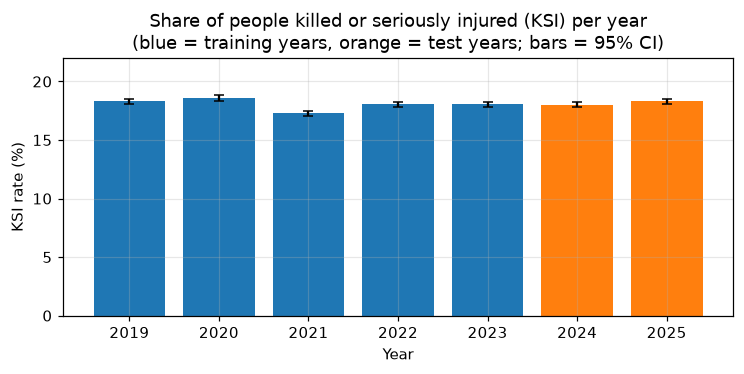

In [2]:
by_year = persons.groupby("year").KSI.agg(n="size", k="sum")
by_year["rate"] = by_year.k / by_year.n
by_year["ci_low"], by_year["ci_high"] = wilson_ci(by_year.k.to_numpy(), by_year.n.to_numpy())
display(by_year.assign(rate_pct=lambda d: (100 * d.rate).round(2)))
print(f"Train KSI rate: {train.KSI.mean():.2%}   Test KSI rate: {test.KSI.mean():.2%}")
print(f"A model that always says 'not KSI' would get {1 - train.KSI.mean():.1%} accuracy -> accuracy is useless here.")

fig, ax = plt.subplots(figsize=(7, 3.5))
colors = ["tab:blue" if y in TRAIN_YEARS else "tab:orange" for y in by_year.index]
ax.bar(by_year.index.astype(str), 100 * by_year.rate, color=colors,
       yerr=[100 * (by_year.rate - by_year.ci_low), 100 * (by_year.ci_high - by_year.rate)], capsize=3)
ax.set(title="Share of people killed or seriously injured (KSI) per year\n(blue = training years, orange = test years; bars = 95% CI)",
       xlabel="Year", ylabel="KSI rate (%)", ylim=(0, 22))
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_01_ksi_by_year.png"); plt.show()

## 2. Missing values (training years)
Share of empty values per column, after `clean.py` converted every 'unknown' code to NaN.

,missing_%
secu3,98.71
etatp,92.25
actp,92.23
larrout,89.99
locp,45.14
secu2,40.11
trajet,27.24
motor,7.42
senc,6.52
manv,5.85


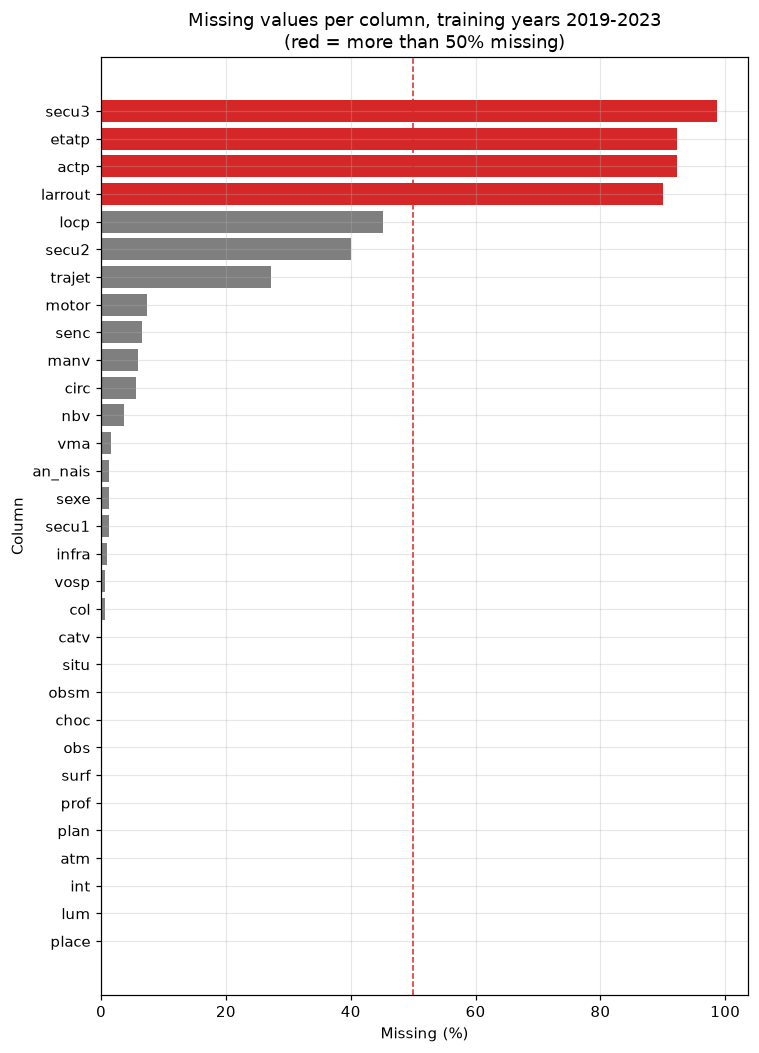

In [3]:
miss = (100 * train.isna().mean()).sort_values(ascending=False)
miss = miss[miss > 0]
display(miss.round(2).to_frame("missing_%"))

fig, ax = plt.subplots(figsize=(7, 0.28 * len(miss) + 1))
ax.barh(miss.index[::-1], miss.values[::-1], color=["tab:red" if v > 50 else "tab:gray" for v in miss.values[::-1]])
ax.axvline(50, color="tab:red", ls="--", lw=1)
ax.set(title="Missing values per column, training years 2019-2023\n(red = more than 50% missing)", xlabel="Missing (%)", ylabel="Column")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_02_missing.png"); plt.show()

## 3. Implausible values
**Speed limit (`vma`)**: French limits go from about 10 to 130 km/h. **Age**: computed as year − birth year.

`persons.parquet` already contains the fix (`fix_implausible` in `make_dataset.py`), so here we look at the cleaned tables **before** that fix, training years only, to show why it was needed.

In [4]:
from src.data.load import load_table
from src.data.clean import clean_table

lieux_raw = clean_table(load_table("lieux", TRAIN_YEARS))
v = lieux_raw.vma.value_counts().sort_index()
odd = v[(v.index < 10) | (v.index > 130)]
print(f"Location rows with vma outside 10-130 km/h: {int(odd.sum())} ({odd.sum() / lieux_raw.vma.notna().sum():.3%} of known values)")
print(odd.to_dict())
print("Most common speed limits:", v.sort_values(ascending=False).head(8).to_dict())

users_raw = clean_table(load_table("usagers", TRAIN_YEARS))
age_raw = users_raw.year - users_raw.an_nais
print(f"\nAge before fix: min {age_raw.min():.0f}, max {age_raw.max():.0f}; older than 100: {(age_raw > 100).sum()}")

age = train.year - train.an_nais
print(f"\nAfter fix (persons.parquet): vma range {train.vma.min():.0f}-{train.vma.max():.0f} km/h, max age {age.max():.0f}")

Location rows with vma outside 10-130 km/h: 332 (0.118% of known values)
{1.0: 67, 2.0: 47, 3.0: 9, 4.0: 4, 5.0: 106, 6.0: 27, 7.0: 3, 8.0: 2, 9.0: 1, 140.0: 1, 180.0: 1, 300.0: 7, 500.0: 41, 501.0: 1, 502.0: 1, 520.0: 1, 560.0: 1, 600.0: 1, 700.0: 4, 770.0: 1, 800.0: 1, 900.0: 4, 901.0: 1}
Most common speed limits: {50.0: 147446, 80.0: 39750, 30.0: 36189, 90.0: 20085, 70.0: 19772, 110.0: 9703, 130.0: 5203, 20.0: 836}



Age before fix: min 0, max 120; older than 100: 215

After fix (persons.parquet): vma range 10-130 km/h, max age 100


## 4. KSI rate by circumstance (training years, 95% CI)
Simple percentages: they show **associations**, not causes, and factors overlap (e.g. trees are mostly beside fast rural roads).

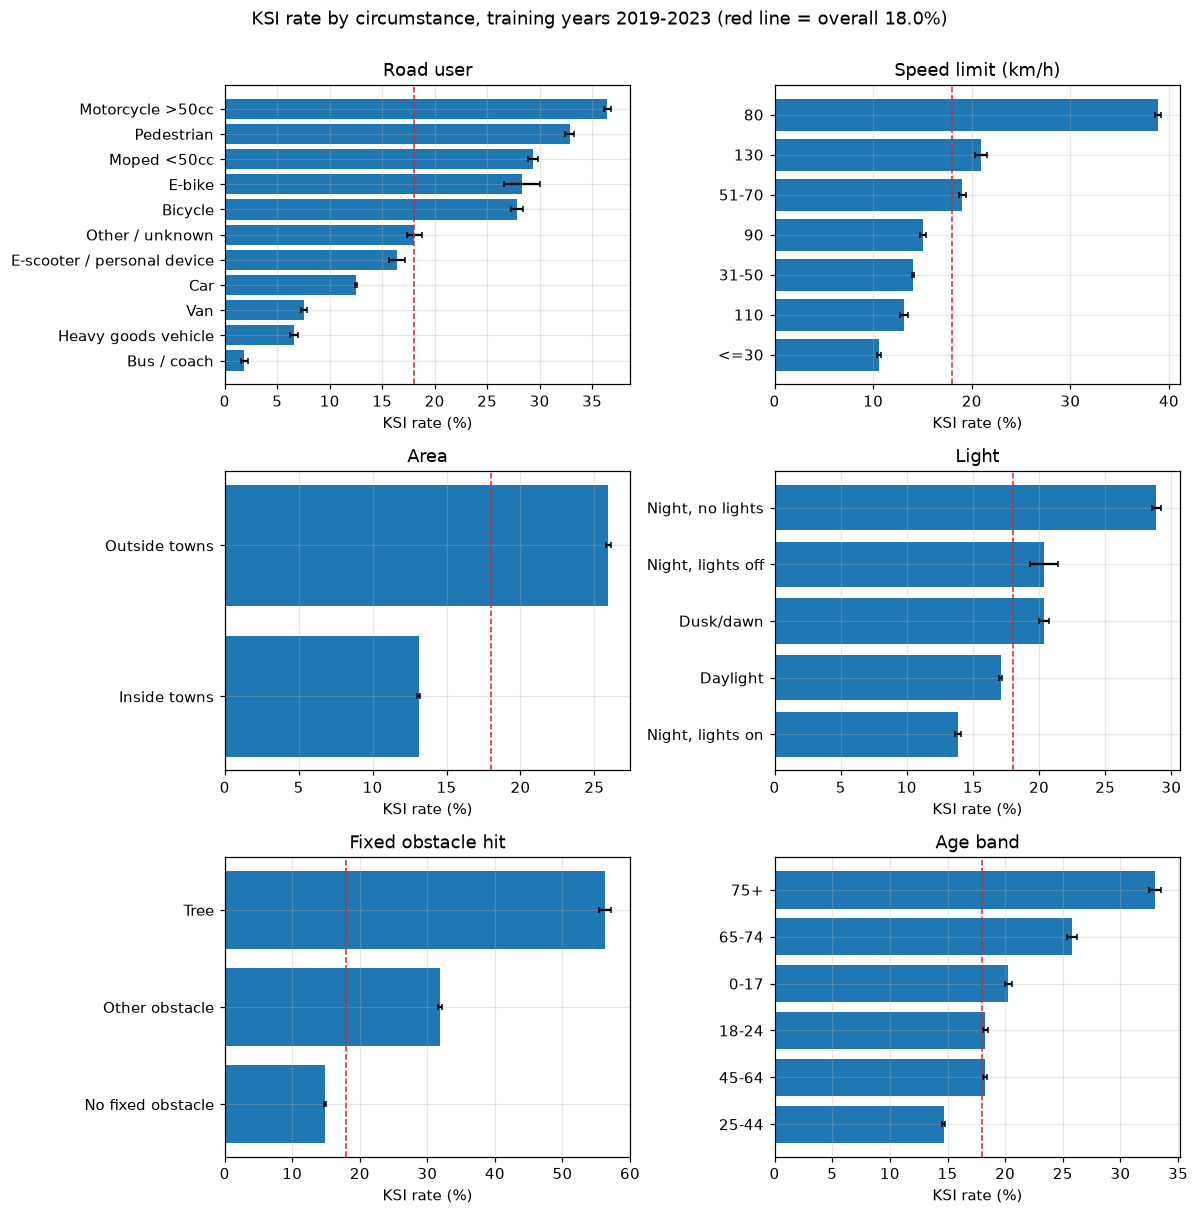

Road user              highest: Motorcycle >50cc 36.4% (n=69,870)  lowest: Bus / coach 1.8%
Speed limit (km/h)     highest: 80 38.9% (n=87,108)  lowest: <=30 10.6%
Area                   highest: Outside towns 26.0% (n=236,815)  lowest: Inside towns 13.1%
Light                  highest: Night, no lights 28.9% (n=62,693)  lowest: Night, lights on 13.9%


Fixed obstacle hit     highest: Tree 56.3% (n=11,123)  lowest: No fixed obstacle 14.8%
Age band               highest: 75+ 33.0% (n=29,392)  lowest: 25-44 14.7%


In [5]:
train["road_user"] = road_user(train)
train["age_band"] = age_band(train)
train["speed_limit"] = pd.cut(train.vma.where(train.vma.between(10, 130)), [0, 30, 50, 70, 80, 90, 110, 130],
                              labels=["<=30", "31-50", "51-70", "80", "90", "110", "130"])
train["area"] = train["agg"].map({"1": "Outside towns", "2": "Inside towns"})
train["light"] = train.lum.map({"1": "Daylight", "2": "Dusk/dawn", "3": "Night, no lights", "4": "Night, lights off", "5": "Night, lights on"})
train["obstacle"] = np.where(train.obs == "2", "Tree", np.where(train.obs == "0", "No fixed obstacle", "Other obstacle"))
train.loc[train.obs.isna(), "obstacle"] = np.nan

panels = [("road_user", "Road user"), ("speed_limit", "Speed limit (km/h)"), ("area", "Area"),
          ("light", "Light"), ("obstacle", "Fixed obstacle hit"), ("age_band", "Age band")]
fig, axes = plt.subplots(3, 2, figsize=(11, 11))
overall = 100 * train.KSI.mean()
for ax, (col, label) in zip(axes.ravel(), panels):
    t = rate_table(train, col)
    ax.barh(t.index.astype(str)[::-1], 100 * t.rate[::-1],
            xerr=[100 * (t.rate - t.ci_low)[::-1], 100 * (t.ci_high - t.rate)[::-1]], color="tab:blue", capsize=2)
    ax.axvline(overall, color="tab:red", ls="--", lw=1)
    ax.set(title=label, xlabel="KSI rate (%)")
fig.suptitle(f"KSI rate by circumstance, training years 2019-2023 (red line = overall {overall:.1f}%)", y=1.0)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_03_ksi_by_factor.png"); plt.show()

for col, label in panels:
    t = rate_table(train, col)
    print(f"{label:22} highest: {t.index[0]} {t.rate.iloc[0]:.1%} (n={t.n.iloc[0]:,})  lowest: {t.index[-1]} {t.rate.iloc[-1]:.1%}")

## 5. Which variables are most associated with KSI?
**Cramér's V** (0 = no association, 1 = perfect), from the chi-square test of independence. Missing values count as their own category. Note: with 600,000 rows almost every chi-square test is 'significant', so we compare the **strength** (V), not p-values.

,cramers_v
secu1,0.289
secu2,0.274
dep,0.270
road_user,0.257
locp,0.247
catv,0.239
obs,0.233
speed_limit,0.233
col,0.228
situ,0.213


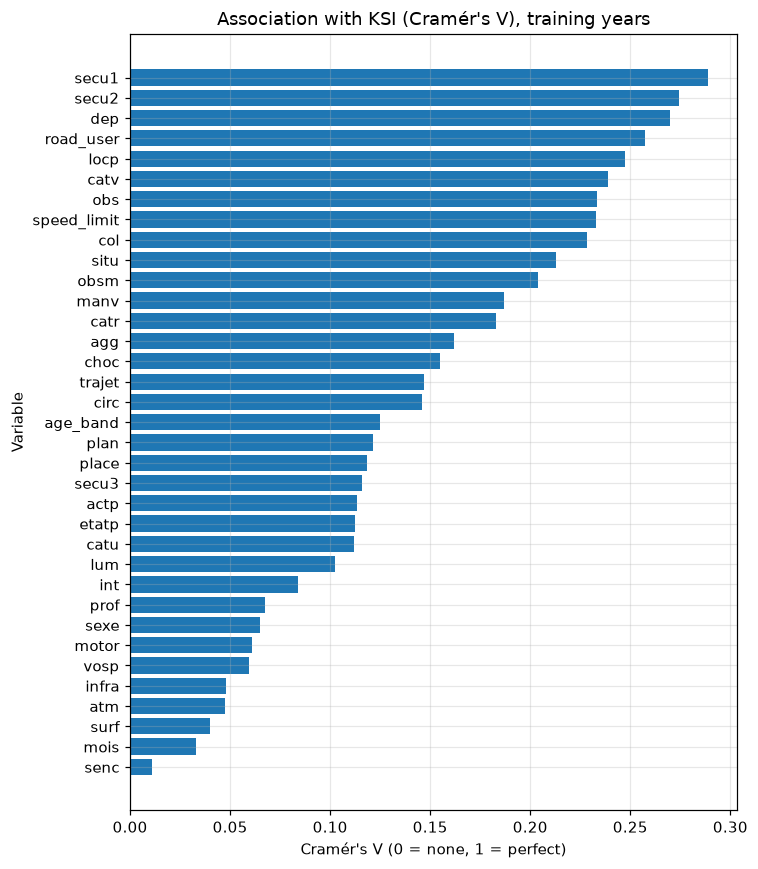

In [6]:
cat_cols = ["catu", "place", "sexe", "trajet", "secu1", "secu2", "secu3", "locp", "actp", "etatp", "lum", "agg", "int", "atm",
            "col", "catr", "circ", "vosp", "prof", "plan", "surf", "infra", "situ", "senc", "catv", "obs", "obsm", "choc", "manv",
            "motor", "dep", "mois", "road_user", "age_band", "speed_limit"]
assoc = pd.Series({c: cramers_v(train[c], train.KSI) for c in cat_cols}).sort_values(ascending=False)
display(assoc.round(3).to_frame("cramers_v"))

fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(assoc.index[::-1], assoc.values[::-1], color="tab:blue")
ax.set(title="Association with KSI (Cramér's V), training years", xlabel="Cramér's V (0 = none, 1 = perfect)", ylabel="Variable")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_04_cramers_v.png"); plt.show()

## 6. Redundancy between variables
Two variables that say the same thing (e.g. `catu` = pedestrian and `place` = 10) add little. Cramér's V between the top variables.

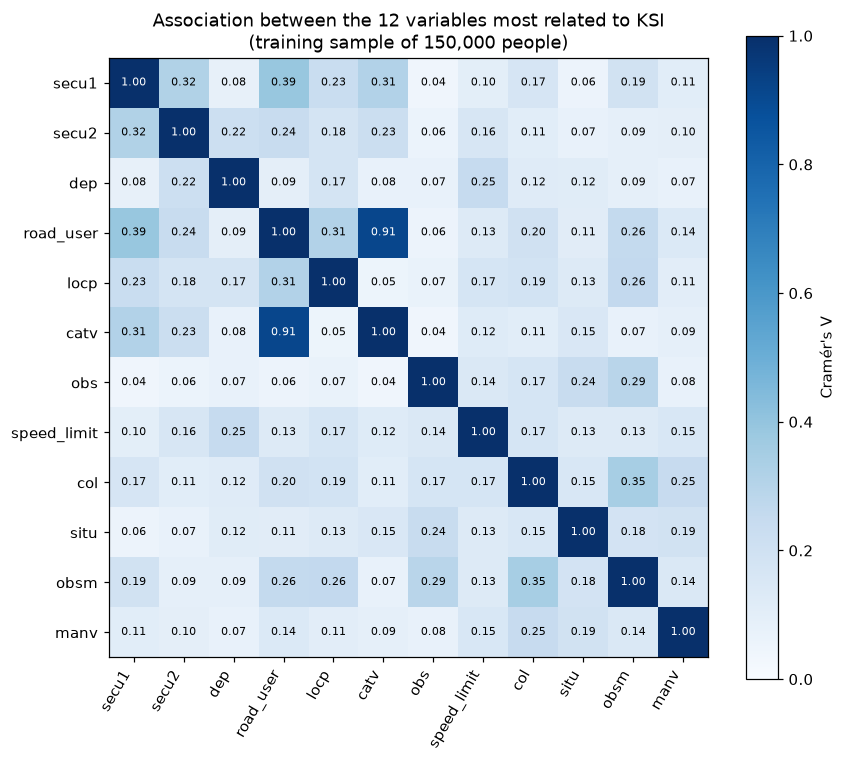

Strongly linked pairs (V > 0.6): [('road_user', 'catv', np.float64(0.91))]


In [7]:
top = list(assoc.index[:12])
sample = train.sample(150_000, random_state=RANDOM_STATE)  # pairwise tests are slow; a sample is enough to measure strength
mat = pd.DataFrame([[cramers_v(sample[a], sample[b]) for b in top] for a in top], index=top, columns=top)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(top)), top, rotation=60, ha="right"); ax.set_yticks(range(len(top)), top)
for i in range(len(top)):
    for j in range(len(top)):
        ax.text(j, i, f"{mat.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if mat.iloc[i, j] > 0.6 else "black")
fig.colorbar(im, label="Cramér's V")
ax.set_title("Association between the 12 variables most related to KSI\n(training sample of 150,000 people)")
ax.grid(False); fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_05_redundancy.png"); plt.show()

pairs = [(a, b, mat.loc[a, b]) for i, a in enumerate(top) for b in top[i + 1:] if mat.loc[a, b] > 0.6]
print("Strongly linked pairs (V > 0.6):", [(a, b, round(v, 2)) for a, b, v in sorted(pairs, key=lambda x: -x[2])])

## 7. Drift: does 2024–2025 look like 2019–2023?
If the test years are very different, a model trained on the past may work worse. We compare category shares with the **total variation distance** (TVD): half the sum of absolute differences in shares, from 0 (identical) to 1 (completely different).

In [8]:
def tvd(a, b):
    pa = a.astype("string").fillna("missing").value_counts(normalize=True)
    pb = b.astype("string").fillna("missing").value_counts(normalize=True)
    return 0.5 * pa.subtract(pb, fill_value=0).abs().sum()

raw_cols = [c for c in cat_cols if c in test.columns]
drift = pd.Series({c: tvd(train[c], test[c]) for c in raw_cols}).sort_values(ascending=False)
display(drift.head(10).round(3).to_frame("TVD train vs test"))
print(f"KSI rate train {train.KSI.mean():.2%} vs test {test.KSI.mean():.2%}")

,TVD train vs test
secu3,0.082
dep,0.071
motor,0.067
locp,0.036
secu2,0.035
catv,0.034
mois,0.032
trajet,0.032
vosp,0.028
manv,0.028


KSI rate train 18.03% vs test 18.16%


## 8. Findings and decisions

| # | Finding (training years unless stated) | Decision / message for the team |
|---|---|---|
| 1 | KSI = **18.0%** in training, 18.2% in test, stable per year (17.3–18.6%). Always predicting "not KSI" gives 82% accuracy. | Imbalanced target: use PR-AUC, recall, precision, F2, never accuracy alone (M3). |
| 2 | `lartpc` (99.8%) and `occutc` (98.7%) are almost empty. | **Dropped** in `make_dataset.py`. |
| 3 | `actp`, `etatp`, `locp` are mostly empty because they only apply to **pedestrians**; `secu2`/`secu3` are empty when there is no 2nd/3rd equipment. Here "missing" carries meaning (missing not at random). | Kept. M2 should not impute them blindly; e.g. build "belt used" / "helmet used" from `secu1-3` together. |
| 4 | 332 location rows had speed limits of 1–9 or 140–901 km/h (pattern suggests typing errors such as 500 for 50). 215 people were "older than 100". | Set to missing (`fix_implausible`). Domain rule, not learned from data. |
| 5 | **Format bug:** `mois` and `dep` were written `1` in 2019–2021 but `01` from 2022, so the same month looked like two categories. Found because `mois` showed a huge train/test drift (TVD 0.29). | Fixed in `clean.py` (leading zeros normalised). Drift for `mois` fell to 0.03. Candidate for AI_AUDIT. |
| 6 | Strongest associations with KSI (Cramér's V): safety equipment (`secu1` 0.29), department (0.27), road user (0.26), obstacle (0.23), speed limit (0.23), collision type (0.23). | Expected risk factors are confirmed. `dep` has 107 categories, which inflates V: treat with care (M2). |
| 7 | KSI rate: tree hit **56%**, motorcycle **36%**, 80 km/h roads **39%**, night without lights **29%**, age 75+ **33%** vs ≤30 km/h 11%, inside towns 13%. | Associations, not causes; factors overlap → this is why we need a model. |
| 8 | `road_user` and `catv` are strongly linked (V = 0.91), as expected (one is built from the other). | Use only one of them in a model. |
| 9 | Drift train → test is small overall, but `secu3` is filled for 1.3% of people in training vs 9.5% in test (recording practice changed), and the share of Paris (`dep` 75) changes. | Avoid features whose **recording** changed (raw `secu3`); check model performance per test year (M3/M4). |
